In [1]:
import numpy as np
import arviz as az 
import pymc as pm
import matplotlib.pyplot as plt
from scipy.stats import chi2
from matplotlib.patches import Ellipse
from scipy.stats import multivariate_normal, poisson

### Sampling from an Exponential PDF

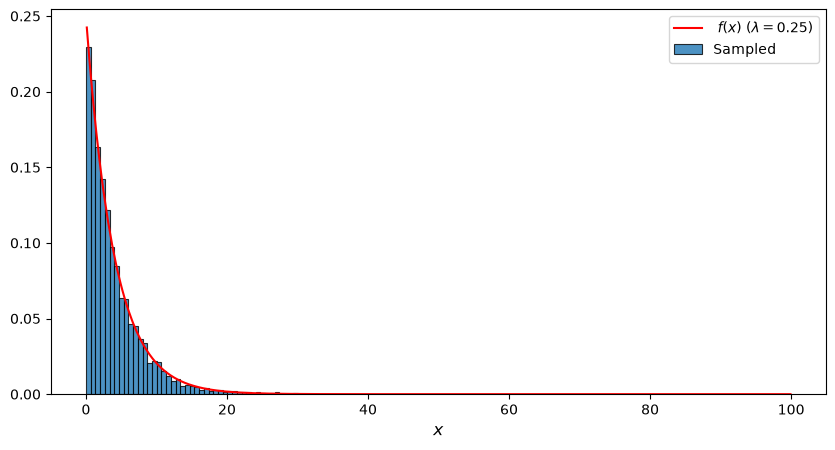

In [3]:
rng = np.random.default_rng(seed=42)

fig, ax = plt.subplots(figsize=(10, 5))

lam = 0.25
x = rng.uniform(0,100,1000)
x.sort()

fx = lam * np.exp(-x*lam)
ax.plot(x,fx,c="red",label = fr" $f(x)$ ($\lambda ={lam}$)")

u = rng.uniform(size=5000)
x_sampled =  - np.log(1-u)/lam

ax.hist(
        x_sampled,
        bins=50,
        density=True,
        alpha=0.8,
        label="Sampled",
        edgecolor="black",
        linewidth=0.8
    )

ax.set_xlabel(r"$x$", fontsize = 12)

plt.legend()
plt.show()

### Sampling from a Bivariate Normal distribution PDF

In [4]:
A = rng.uniform(0,2,size=(2,2))
Sigma = A @ A.T  +0.1*np.eye(2)

mu = np.array([0,5])

L = np.linalg.cholesky(Sigma)
I  = np.identity(2)
N = 10000
z = rng.standard_normal((N,2))

x = z @ L.T + mu.T

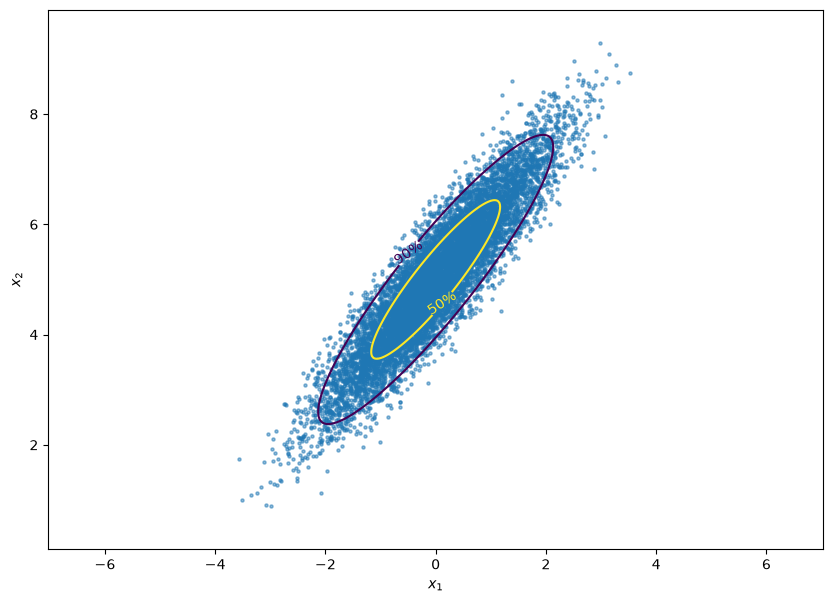

In [5]:
sd = np.sqrt(np.diag(Sigma))
x1 = np.linspace(mu[0] - 4*sd[0], mu[0] + 4*sd[0], 300)
x2 = np.linspace(mu[1] - 4*sd[1], mu[1] + 4*sd[1], 300)
X1, X2 = np.meshgrid(x1, x2)
Z = multivariate_normal(mean=mu, cov=Sigma).pdf(np.dstack((X1, X2)))

fig, ax = plt.subplots(figsize = (10,7))


ax.scatter(x[:,0], x[:,1], s=5, alpha=0.5, label="Sampled points")
# k = np.sqrt(5.991)        
# w, v = np.linalg.eigh(Sigma)
# ang = np.degrees(np.arctan2(v[1, 1], v[0, 1]))
# ax.add_patch(Ellipse(
#     xy=mu,
#     width=2*k*np.sqrt(w[1]),
#     height=2*k*np.sqrt(w[0]),
#     angle=ang,
#     fill=False,
#     ec='r',
#     lw=2
# ))
# contours = ax.contour(X1, X2, Z, levels=5)

probs = [0.5, 0.9]
r2 = chi2.ppf(probs, df=2)
levels = np.exp(-r2/2) / (2*np.pi*np.sqrt(np.linalg.det(Sigma)))
cs = ax.contour(X1, X2, Z, levels=np.sort(levels))
ax.clabel(cs, fmt={l: f"{p:.0%}" for l, p in zip(np.sort(levels), probs[::-1])})

plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")
ax.axis("equal")
plt.show()

In [6]:
print(f"mu = {mu}")
print(f"Sample mean: {np.mean(x, axis=0)}")

print("\nCovariance:\n", Sigma)
print("\nSample covariance:\n", np.cov(x, rowvar=False))

mu = [0 5]
Sample mean: [0.0077039  5.01966774]

Covariance:
 [[0.98634381 1.11135147]
 [1.11135147 1.49371347]]

Sample covariance:
 [[0.97538083 1.09910392]
 [1.09910392 1.4849294 ]]


### Metropolis Hastings

In [7]:
def proposal_distribution(x, mu, Sigma):
    return multivariate_normal.pdf(x, mean=mu, cov=Sigma)


def sample_proposal_distribution(mu,N):

    Sigma = 2.5*np.identity(2)
    L = np.linalg.cholesky(Sigma)
    z = rng.standard_normal((N,2))

    return z @ L.T + mu.T

def evaluate_banana_pdf(x, b=0.1, sigma=2.0):
    x = np.atleast_2d(x)
    x1, x2 = x[:, 0], x[:, 1]
    
    y1 = x1
    y2 = x2 + b * (x1**2) - b * (sigma**2)
    unwarped = np.column_stack([y1, y2])

    underlying_gaussian = multivariate_normal(mean=[0.0, 0.0], cov=[sigma**2, 1.0])
    return underlying_gaussian.pdf(unwarped)


def alfa(x,y, b, sigma):

    rho = evaluate_banana_pdf(y, b=b, sigma=sigma)  / evaluate_banana_pdf(x, b=b, sigma=sigma) 
    return min([1, rho])


### Banana-shaped probability distribution

The target probability density is given by

$$
\pi(x_1,x_2)\propto
\exp\left[
-\frac{1}{2}\frac{x_1^2}{\sigma_1^2}
-\frac{1}{2}
\frac{\left(x_2-Bx_1^2+B\sigma_1^2\right)^2}{\sigma_2^2}
\right].
$$

where:

- $\sigma_1^2$: Variance of the first coordinate.
- $\sigma_2^2$: Conditional variance of the second coordinate.
- $B$: Curvature parameter controlling the banana shape.

For our numerical example, we choose

$$
\sigma_1=2,\qquad \sigma_2=1,\qquad B=-0.1.
$$

Therefore, the target density becomes

$$
\pi(x_1,x_2)\propto
\exp\left[
-\frac{x_1^2}{8}
-\frac{1}{2}
\left(x_2+0.1x_1^2-0.4\right)^2
\right].
$$


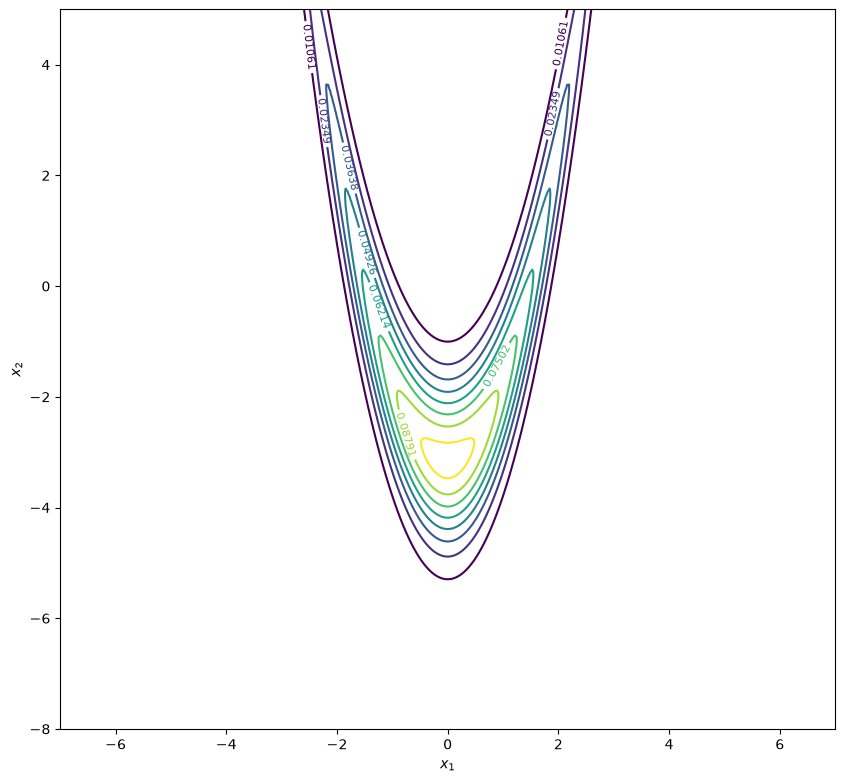

In [8]:
rng = np.random.default_rng(42)

N = 100
b = -1.4
sigma = 1.5

y = rng.multivariate_normal(
    mean=[0, 0],
    cov=[[sigma**2, 0], [0, 1]],
    size=N
)

x = np.column_stack([
    y[:, 0],
    y[:, 1] - b * (y[:, 0]**2 - sigma**2)
])


x1 = np.linspace(-7, 7, 400)
x2 = np.linspace(-8, 5, 400)

X1, X2 = np.meshgrid(x1, x2)


points = np.column_stack([X1.ravel(), X2.ravel()])
Z = evaluate_banana_pdf(points, b=b, sigma=sigma).reshape(X1.shape)


fig, ax = plt.subplots(figsize=(10, 10))

levels = np.linspace(0.1, 0.95, 8) * Z.max()   
contours = ax.contour(X1, X2, Z, levels=levels, cmap="viridis")

ax.clabel(contours, inline=True, fontsize=8)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_xlim(-7, 7)
ax.set_ylim(-8, 5)
ax.set_aspect("equal", adjustable="box")

# ax.legend()

plt.show()

In [9]:
rng = np.random.default_rng(seed=45)
xt = np.array([2,3])
chain = []
accepted = 1
lenght_chain = 20000

for _ in range(lenght_chain):

    # sample candidate
    y = sample_proposal_distribution( xt.reshape(-1),1 ).reshape(-1) 
    u = rng.uniform()

    if u <= alfa(xt, y, b,sigma):
        accepted += 1
        xt = y

    chain.append(xt.copy())

chain = np.array(chain)

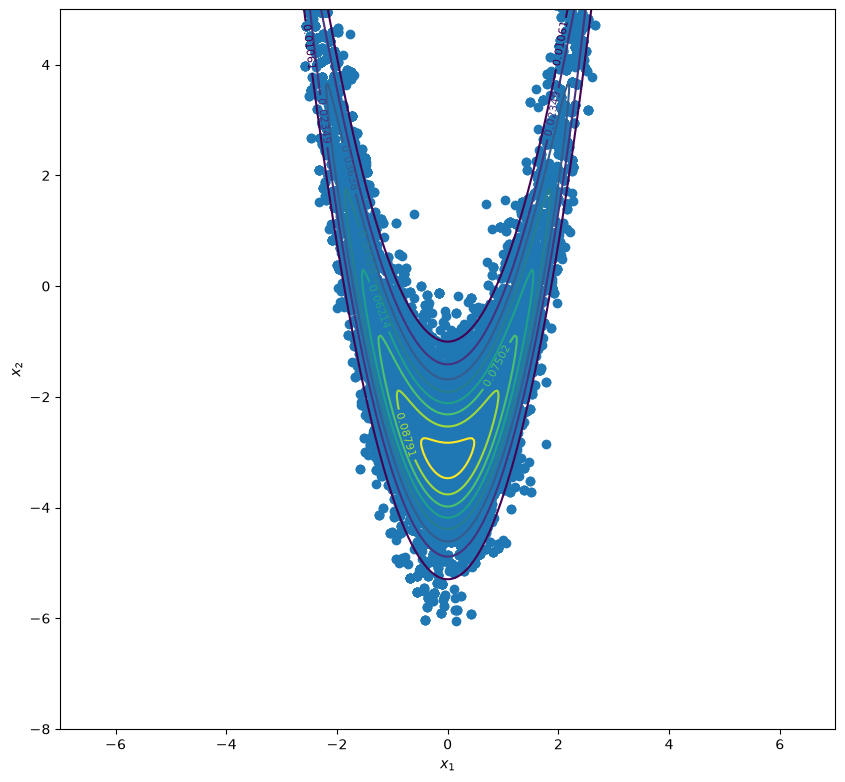

In [10]:
y = rng.multivariate_normal(
    mean=[0, 0],
    cov=[[sigma**2, 0], [0, 1]],
    size=N
)

x = np.column_stack([
    y[:, 0],
    y[:, 1] - b * (y[:, 0]**2 - sigma**2)
])

# Construct grid covering the samples
x1 = np.linspace(-7, 7, 400)
x2 = np.linspace(-8, 5, 400)
# x1 = np.linspace(x[:, 0].min()-1, x[:, 0].max()+1, 300)
# x2 = np.linspace(x[:, 1].min()-1, x[:, 1].max()+1, 300)

X1, X2 = np.meshgrid(x1, x2)

# Evaluate the density at each grid point
points = np.column_stack([X1.ravel(), X2.ravel()])
Z = evaluate_banana_pdf(points, b=b, sigma=sigma).reshape(X1.shape)

# Plot
fig, ax = plt.subplots(figsize=(10, 10))

levels = np.linspace(0.1, 0.95, 8) * Z.max()   
contours = ax.contour(X1, X2, Z, levels=levels, cmap="viridis")

ax.clabel(contours, inline=True, fontsize=8)

ax.scatter(chain[:,0], chain[:,1])

ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_xlim(-7, 7)
ax.set_ylim(-8, 5)
ax.set_aspect("equal", adjustable="box")

# ax.legend()

plt.show()

In [11]:
print(f"Acceptance rate: {accepted/lenght_chain:.2%}")

Acceptance rate: 27.08%


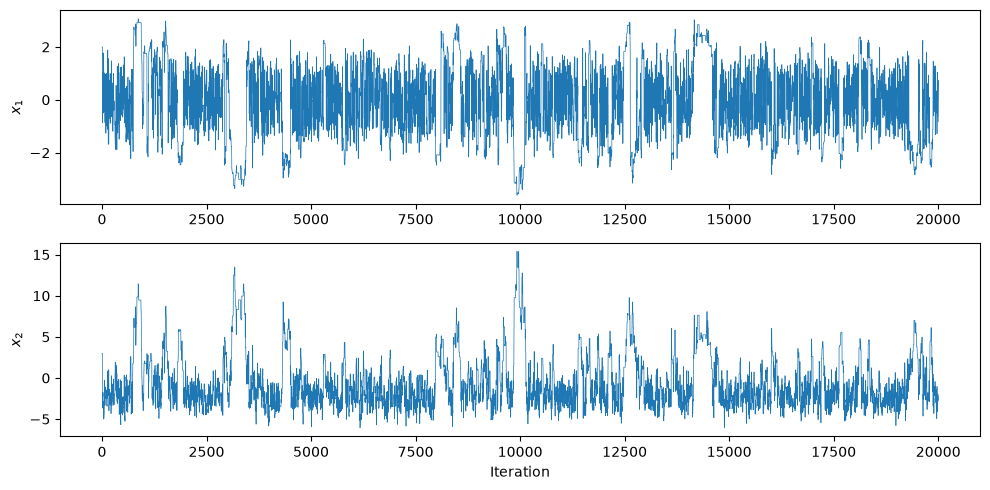

In [12]:
fig, ax = plt.subplots(2, 1, figsize=(10, 5))

ax[0].plot(chain[:, 0], lw=0.5)
ax[0].set_ylabel(r"$x_1$")

ax[1].plot(chain[:, 1], lw=0.5)
ax[1].set_ylabel(r"$x_2$")
ax[1].set_xlabel("Iteration")

plt.tight_layout()
plt.show()